In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt


In [2]:
data_path = r"C:\Users\Ā\Documents\python_class\dataset\India_Pincodes\India_Pincodes"

In [3]:
# Load pincode data
pincodes = gpd.read_file(
    data_path + r"\All_India_pincode_Boundary-19312_shp.shp"
)

In [4]:
# Load railway data
rails = gpd.read_file(
    r"C:\Users\Ā\Documents\python_class\dataset\ind_railways_lines.geojson"
)


In [5]:
print("Pincodes:", pincodes.shape)
print("Railways:", rails.shape)

print("Pincode CRS:", pincodes.crs)
print("Railway CRS:", rails.crs)

Pincodes: (19312, 6)
Railways: (89129, 14)
Pincode CRS: EPSG:4326
Railway CRS: EPSG:4326


In [6]:
# Select only Tirupati Division

tirupati = pincodes[
    pincodes["Division"] == "Tirupati"
].copy()

print("Number of Tirupati pincode polygons:", len(tirupati))

Number of Tirupati pincode polygons: 57


In [7]:
# Dissolve the Tirupati pincode polygons

tirupati_boundary = tirupati.dissolve()

print("Features after dissolve:", len(tirupati_boundary))

Features after dissolve: 1


In [8]:
# Check CRS of both layers

print("Tirupati CRS:", tirupati_boundary.crs)
print("Railway CRS:", rails.crs)

Tirupati CRS: EPSG:4326
Railway CRS: EPSG:4326


In [9]:
# Make sure both layers have the same CRS

if rails.crs != tirupati_boundary.crs:
    rails = rails.to_crs(tirupati_boundary.crs)

print("Tirupati CRS:", tirupati_boundary.crs)
print("Railway CRS:", rails.crs)

Tirupati CRS: EPSG:4326
Railway CRS: EPSG:4326


In [10]:
# Clip railway lines using the Tirupati boundary

rails_tirupati = gpd.clip(
    rails,
    tirupati_boundary
)

print("Railway features before clip:", len(rails))
print("Railway features after clip:", len(rails_tirupati))

Railway features before clip: 89129
Railway features after clip: 352


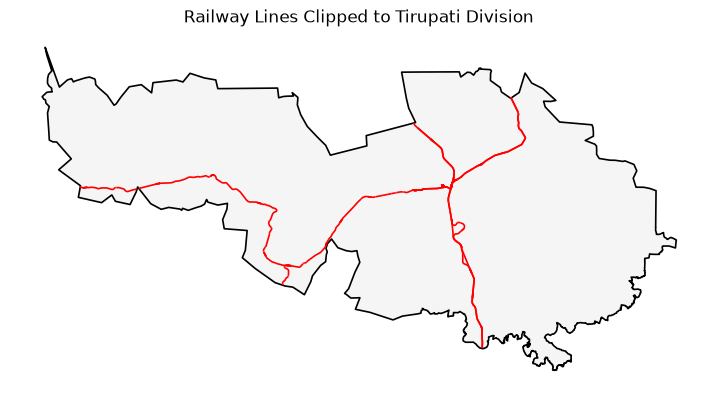

In [11]:
# Final map: Tirupati boundary + clipped railway lines

fig, ax = plt.subplots(figsize=(9, 9))

# Tirupati Division boundary
tirupati_boundary.plot(
    ax=ax,
    facecolor="whitesmoke",
    edgecolor="black",
    linewidth=1.2,
    zorder=1
)

# Railway lines after clipping
rails_tirupati.plot(
    ax=ax,
    color="red",
    linewidth=1.2,
    zorder=2
)

ax.set_title("Railway Lines Clipped to Tirupati Division")
ax.set_axis_off()

plt.show()